In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Monte Carlo simulation

$y_t = c + a_1 y_{t-1} + a_2 y_{t-2} + u_t$, where $u_t \overset{iid}{\sim} N(0,\sigma^2)$

In [2]:
# Parameters
c = 0.0
a1 = 0.8
a2 = 0.1
sigma = 1.0
T_sim = 100 # sample size

# Monte Carlo settings
B_sim = 1000 # number of iterations
rng = np.random.default_rng(31150)

In [3]:
def simulate_ar2(param, u, y_init):
    """ Simulate AR(2) process given innovations """
    y_sim = np.empty(len(u) + 2)
    y_sim[:2] = y_init
    for t in range(2, len(y_sim)):
        y_sim[t] = param[0] + param[1] * y_sim[t - 1] + param[2] * y_sim[t - 2] + u[t-2]
    return y_sim

# Monte Carlo
param_hat_sim = np.empty((B_sim, 3))
for b in range(B_sim):
    u = rng.normal(0, sigma, T_sim-2)
    y_sim = simulate_ar2([c, a1, a2], u, np.zeros(2)) # initialize with zeros
    result = sm.tsa.AutoReg(y_sim, lags=2).fit()
    param_hat_sim[b] = result.params
a1_hat_sim = param_hat_sim[:, 1]

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


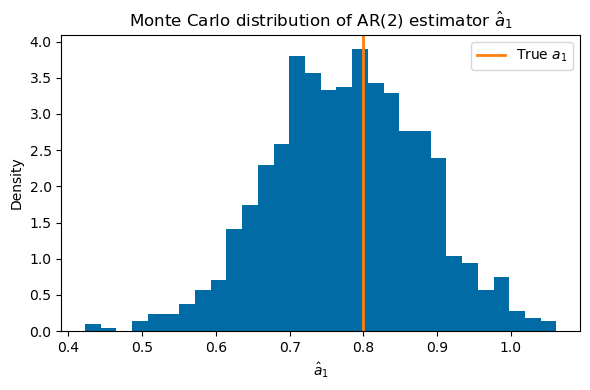

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(a1_hat_sim, bins=30, color='C0', density=True)
ax.axvline(a1, color='C1', linewidth=2, label='True $a_1$')
ax.set_xlabel('$\\hat a_1$')
ax.set_ylabel('Density')
ax.set_title('Monte Carlo distribution of AR(2) estimator $\\hat a_1$')
ax.legend()
plt.tight_layout()
fig.savefig('output/ar2_mc_hist.eps')
plt.show()

## Bootstrap

In [5]:
# Load data
df = pd.read_csv('data/CPIAUCSL.csv', index_col='observation_date', parse_dates=True)
df = df.interpolate() # interpolate missing value in Oct 2025
cpi = df['CPIAUCSL'].values
y = 100*np.diff(np.log(cpi)) # monthly inflation rate

In [6]:
# Estimate AR(2) model
result = sm.tsa.AutoReg(y, lags=2).fit()
print(result.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  949
Model:                     AutoReg(2)   Log Likelihood                -113.499
Method:               Conditional MLE   S.D. of innovations              0.273
Date:                Wed, 03 Jun 2026   AIC                            234.999
Time:                        14:00:22   BIC                            254.412
Sample:                             2   HQIC                           242.397
                                  949                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1081      0.012      8.823      0.000       0.084       0.132
y.L1           0.5047      0.032     15.802      0.000       0.442       0.567
y.L2           0.1126      0.032      3.529      0.0

In [7]:
# Recursive residual bootstrap
param_hat = result.params
u_hat = result.resid # residuals (length T-2)
T = len(y)

B = 1000 # number of bootstrap samples

param_hat_boot = np.empty((B, 3))
for b in range(B):
    # Resample residuals with replacement
    u_boot = rng.choice(u_hat, size=T - 2, replace=True)
    # Initial values: random pair of consecutive obs.
    i0 = rng.integers(0, T - 1)
    y_init = y[i0:i0 + 2]
    # Simulate bootstrap sample and estimate
    y_boot = simulate_ar2(param_hat, u_boot, y_init)
    result_boot = sm.tsa.AutoReg(y_boot, lags=2).fit()
    param_hat_boot[b] = result_boot.params

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


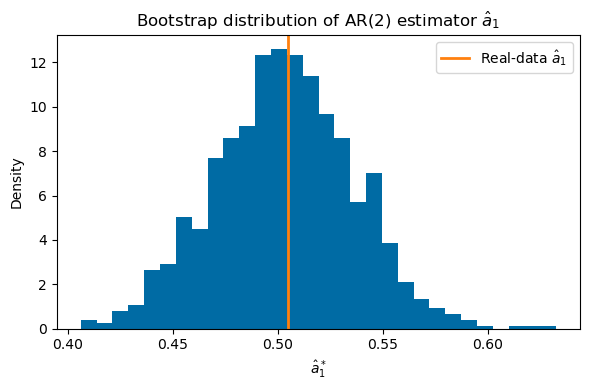

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(param_hat_boot[:, 1], bins=30, color='C0', density=True)
ax.axvline(param_hat[1], color='C1', linewidth=2, label='Real-data $\\hat a_1$')
ax.set_xlabel('$\\hat a_1^*$')
ax.set_ylabel('Density')
ax.set_title('Bootstrap distribution of AR(2) estimator $\\hat a_1$')
ax.legend()
plt.tight_layout()
fig.savefig('output/ar2_boot_hist.eps')
plt.show()

In [9]:
# Bootstrap SE
se_boot = np.std(param_hat_boot, axis=0, ddof=1)

# Bootstrap confidence intervals
signif = 0.05
ci_lower = 2*param_hat - np.quantile(param_hat_boot, 1 - signif/2, axis=0)
ci_upper = 2*param_hat - np.quantile(param_hat_boot, signif/2, axis=0)

# Results table
results_table = pd.DataFrame({
    'Estimate': param_hat,
    'SE': se_boot,
    'CI lower': ci_lower,
    'CI upper': ci_upper,
}, index=['const', 'a1', 'a2']).round(4)
print(results_table)

       Estimate      SE  CI lower  CI upper
const    0.1081  0.0125    0.0810    0.1302
a1       0.5047  0.0331    0.4430    0.5700
a2       0.1126  0.0317    0.0532    0.1811
